# SIS 1 - Population and Country Area Analysis

## 1. Data Sources
- World Bank API: indicator SP.POP.TOTL (country + population, year 2024)
- Wikipedia: List of countries and dependencies by area (country + area, static HTML)

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from bs4 import BeautifulSoup

## 2. World Bank API Collection

In [2]:
api_url = "https://api.worldbank.org/v2/country/all/indicator/SP.POP.TOTL"

In [3]:
params = {
    "format": "json",
    "date": 2024,
    "per_page": 500
}

In [4]:
response = requests.get(
    api_url,
    params=params,
    timeout=20
)

In [5]:
response.status_code

200

In [6]:
api_json = response.json()

In [7]:
type(api_json)

list

In [8]:
len(api_json)

2

In [9]:
# first element = metadata
api_json[0]

{'page': 1,
 'pages': 1,
 'per_page': 500,
 'total': 266,
 'sourceid': '2',
 'lastupdated': '2026-10-08'}

In [10]:

api_json[1][0]

{'indicator': {'id': 'SP.POP.TOTL', 'value': 'Population, total'},
 'country': {'id': 'ZH', 'value': 'Africa Eastern and Southern'},
 'countryiso3code': 'AFE',
 'date': '2024',
 'value': 769280888,
 'unit': '',
 'obs_status': '',
 'decimal': 0}

In [11]:
len(api_json[1])

266

In [12]:
records = api_json[1]

In [13]:
api_data = []

for record in records:
    api_data.append({
        "Country": record["country"]["value"],
        "Country_Code": record["countryiso3code"],
        "Population": record["value"],
        "Year": record["date"]
    })

In [14]:
api_df = pd.DataFrame(api_data)

In [15]:
api_df.head()

,Country,Country_Code,Population,Year
0,Africa Eastern and Southern,AFE,769280888.0,2024
1,Africa Western and Central,AFW,520655398.0,2024
2,Arab World,ARB,492612632.0,2024
3,Caribbean small states,CSS,4539060.0,2024
4,Central Europe and the Baltics,CEB,100061963.0,2024


In [16]:
api_df.shape

(266, 4)

In [17]:
api_df.dtypes

,0
Country,object
Country_Code,object
Population,float64
Year,object


In [18]:
api_df.isnull().sum()

,0
Country,0
Country_Code,0
Population,1
Year,0


In [19]:
api_df.duplicated().sum()

np.int64(0)

In [20]:
api_df["Population"] = pd.to_numeric(
    api_df["Population"],
    errors="coerce"
)

In [21]:
api_df["Year"] = api_df["Year"].astype(int)

In [22]:
api_df.dtypes

,0
Country,object
Country_Code,object
Population,float64
Year,int64


### Regions and income groups are not countries

In [23]:
country_url = "https://api.worldbank.org/v2/country"

In [24]:
country_params = {
    "format": "json",
    "per_page": 500
}

In [25]:
country_response = requests.get(
    country_url,
    params=country_params,
    timeout=20
)

In [26]:
country_response.status_code

200

In [27]:
country_json = country_response.json()

In [28]:
country_json[1][0]

{'id': 'ABW',
 'iso2Code': 'AW',
 'name': 'Aruba',
 'region': {'id': 'LCN',
  'iso2code': 'ZJ',
  'value': 'Latin America & Caribbean '},
 'adminregion': {'id': '', 'iso2code': '', 'value': ''},
 'incomeLevel': {'id': 'HIC', 'iso2code': 'XD', 'value': 'High income'},
 'lendingType': {'id': 'LNX', 'iso2code': 'XX', 'value': 'Not classified'},
 'capitalCity': 'Oranjestad',
 'longitude': '-70.0167',
 'latitude': '12.5167'}

In [29]:
region_data = []

for c in country_json[1]:
    region_data.append({
        "Country_Code": c["id"],
        "Region": c["region"]["value"]
    })

In [30]:
region_df = pd.DataFrame(region_data)

In [31]:
region_df.head()

,Country_Code,Region
0,ABW,Latin America & Caribbean
1,AFE,Aggregates
2,AFG,"Middle East, North Africa, Afghanistan & Pakistan"
3,AFR,Aggregates
4,AFW,Aggregates


In [32]:
api_df = pd.merge(
    api_df,
    region_df,
    on="Country_Code",
    how="left"
)

In [33]:
api_df.shape

(266, 5)

In [34]:
api_df["Region"].value_counts()

,count
Region,
Europe & Central Asia,58
Sub-Saharan Africa,48
Aggregates,44
Latin America & Caribbean,42
East Asia & Pacific,37
"Middle East, North Africa, Afghanistan & Pakistan",23
South Asia,6
North America,3


In [35]:
api_df[api_df["Region"] == "Aggregates"]

,Country,Country_Code,Population,Year,Region
0,Africa Eastern and Southern,AFE,7.692809e+08,2024,Aggregates
1,Africa Western and Central,AFW,5.206554e+08,2024,Aggregates
2,Arab World,ARB,4.926126e+08,2024,Aggregates
3,Caribbean small states,CSS,4.539060e+06,2024,Aggregates
4,Central Europe and the Baltics,CEB,1.000620e+08,2024,Aggregates
5,Early-demographic dividend,EAR,3.552306e+09,2024,Aggregates
6,East Asia & Pacific,EAS,2.388319e+09,2024,Aggregates
7,East Asia & Pacific (excluding high income),EAP,2.141122e+09,2024,Aggregates
8,East Asia & Pacific (IDA & IBRD countries),TEA,2.114653e+09,2024,Aggregates
9,Euro area,EMU,3.576034e+08,2024,Aggregates


In [36]:
api_df = api_df[api_df["Region"] != "Aggregates"]

In [37]:
api_df = api_df.drop(columns=["Region"])

In [38]:
api_df = api_df.reset_index(drop=True)

In [39]:
api_df.shape

(222, 4)

In [40]:
api_df.isnull().sum()

,0
Country,0
Country_Code,0
Population,1
Year,0


In [41]:

api_df[api_df["Population"].isnull()]

,Country,Country_Code,Population,Year
3,Not classified,,NaN,2024


In [42]:
api_df = api_df.dropna(subset=["Population"])

In [43]:
api_df = api_df.reset_index(drop=True)

In [44]:
api_df.shape

(221, 4)

In [45]:
api_df.head()

,Country,Country_Code,Population,Year
0,High income,,1.417926e+09,2024
1,Low income,,7.471526e+08,2024
2,Lower middle income,,2.907380e+09,2024
3,Upper middle income,,3.068439e+09,2024
4,Afghanistan,AFG,4.264749e+07,2024


## 3. Static Web Scraping

In [46]:
wiki_url = "https://en.wikipedia.org/wiki/List_of_countries_and_dependencies_by_area"

In [47]:
headers = {"User-Agent": "Mozilla/5.0"}

In [48]:
wiki_response = requests.get(
    wiki_url,
    headers=headers,
    timeout=20
)

In [49]:
wiki_response.status_code

200

In [50]:
soup = BeautifulSoup(
    wiki_response.text,
    "html.parser"
)

In [51]:
tables = soup.find_all(
    "table",
    class_="wikitable"
)

In [52]:
len(tables)

1

In [53]:
for table in tables:
    print(table.find_all("tr")[0].get_text(" ", strip=True))
    print("---")

Country / dependency Total in km 2 (mi 2 ) Land in km 2 (mi 2 ) Inland water in km 2 (mi 2 ) % water
---


In [54]:
area_table = tables[0]

In [55]:
for sup in area_table.find_all("sup"):
    sup.decompose()

In [56]:
rows = area_table.find_all("tr")

In [57]:
len(rows)

278

In [58]:
rows[0].get_text(" ", strip=True)

'Country / dependency Total in km (mi ) Land in km (mi ) Inland water in km (mi ) % water'

In [59]:
rows[1]

<tr id="mwaw">
<td id="mwbA"><span about="#mwt39" data-mw='{"parts":[{"template":{"target":{"wt":"ntsh","href":"./Template:Ntsh"},"params":{"1":{"wt":"0"}},"i":0}}]}' data-sort-value="5000000000000000000♠" id="mwbQ" style="display:none" typeof="mw:Transclusion"></span> –</td><td id="mwbg"><b id="mwbw"><span about="#mwt40" class="flagicon" data-mw='{"parts":[{"template":{"target":{"wt":"noflag","href":"./Template:Noflag"},"params":{"1":{"wt":"[[Earth]]"}},"i":0}}]}' id="mwcA" style="padding-left:25px;" typeof="mw:Transclusion"><span typeof="mw:Entity"> </span></span><a about="#mwt40" href="https://en.wikipedia.org/wiki/Earth" id="mwcQ" rel="mw:WikiLink" title="Earth">Earth</a></b></td><td id="mwcg"><span about="#mwt41" data-mw='{"parts":[{"template":{"target":{"wt":"km2 mi2","href":"./Template:Km2_mi2"},"params":{"1":{"wt":"510072000"}},"i":0}}]}' id="mwcw" typeof="mw:Transclusion">510,072,000 (196,940,000)</span></td><td id="mwdA"><span about="#mwt42" data-mw='{"parts":[{"template":{"t

In [60]:
for cell in rows[1].find_all(["th", "td"]):
    print(cell.get_text(strip=True))

–
Earth
510,072,000 (196,940,000)
148,940,000 (57,506,000)
361,132,000 (139,434,000)
70.8



In [61]:
wiki_data = []

for row in rows[1:]:
    cells = row.find_all(["th", "td"])

    if len(cells) >= 3:
        wiki_data.append({
            "Country": cells[1].get_text(strip=True),
            "Area_Text": cells[2].get_text(strip=True)
        })

In [62]:
wiki_df = pd.DataFrame(wiki_data)

In [63]:
wiki_df.head(10)

,Country,Area_Text
0,Earth,"510,072,000 (196,940,000)"
1,Russia,"17,098,246 (6,601,667)"
2,Antarctica,"14,200,000 (5,480,000)"
3,Canada,"9,984,670 (3,855,100)"
4,China,"9,596,960 (3,705,410)"
5,United States,"9,525,067 (3,677,647)"
6,Brazil,"8,510,346 (3,285,862)"
7,Australia,"7,741,220 (2,988,900)"
8,Australian Antarctic Territory(Australia),"5,896,500 (2,276,700)"
9,India,"3,287,263 (1,269,219)"


In [64]:
wiki_df.shape

(276, 2)

## 4. Data Cleaning

In [65]:
wiki_df["Country"] = (
    wiki_df["Country"]
    .str.split("(")
    .str[0]
    .str.strip()
)

In [66]:

wiki_df["Area_km2"] = (
    wiki_df["Area_Text"]
    .str.split("(")
    .str[0]
    .str.replace(",", "", regex=False)
)

In [67]:
wiki_df["Area_km2"] = pd.to_numeric(
    wiki_df["Area_km2"],
    errors="coerce"
)

In [68]:
wiki_df = wiki_df.drop(columns=["Area_Text"])

In [69]:
wiki_df.head(10)

,Country,Area_km2
0,Earth,510072000.0
1,Russia,17098246.0
2,Antarctica,14200000.0
3,Canada,9984670.0
4,China,9596960.0
5,United States,9525067.0
6,Brazil,8510346.0
7,Australia,7741220.0
8,Australian Antarctic Territory,5896500.0
9,India,3287263.0


In [70]:
wiki_df.dtypes

,0
Country,object
Area_km2,float64


In [71]:
wiki_df.isnull().sum()

,0
Country,0
Area_km2,0


In [72]:
wiki_df = wiki_df.dropna(subset=["Area_km2"])

In [73]:
wiki_df.duplicated().sum()

np.int64(0)

In [74]:
wiki_df["Country"].duplicated().sum()

np.int64(2)

In [75]:
wiki_df[wiki_df["Country"].duplicated(keep=False)]

,Country,Area_km2
51,France,643801.0
58,France,551500.0
72,Norway,386224.0
80,Norway,323802.0


In [76]:
wiki_df = wiki_df.drop_duplicates(subset="Country")

In [77]:
wiki_df = wiki_df.reset_index(drop=True)

In [78]:
wiki_df[wiki_df["Area_km2"] <= 0]

,Country,Area_km2


In [79]:
wiki_df.shape

(274, 2)

In [80]:
wiki_df.dtypes

,0
Country,object
Area_km2,float64


## 5. Data Merging

In [81]:
check_merge = pd.merge(
    api_df,
    wiki_df,
    on="Country",
    how="outer",
    indicator=True
)

In [82]:
check_merge["_merge"].value_counts()

,count
_merge,
both,180
right_only,94
left_only,41


In [83]:
check_merge[check_merge["_merge"] == "left_only"]["Country"]

,Country
22,"Bahamas, The"
42,Brunei Darussalam
46,Cabo Verde
54,Channel Islands
63,"Congo, Dem. Rep."
64,"Congo, Rep."
68,Cote d'Ivoire
71,Curacao
75,Czechia
85,"Egypt, Arab Rep."


In [84]:
check_merge[check_merge["_merge"] == "right_only"]["Country"]

,Country
0,Abkhazia
1,Adélie Land
3,Akrotiri and Dhekelia
9,Anguilla
10,Antarctica
...,...
306,Wales
307,Wallis and Futuna
309,Western Sahara
310,Yemen


In [85]:
name_fixes = {
    "Russian Federation": "Russia",
    "Egypt, Arab Rep.": "Egypt",
    "Iran, Islamic Rep.": "Iran",
    "Korea, Rep.": "South Korea",
    "Korea, Dem. People's Rep.": "North Korea",
    "Turkiye": "Turkey",
    "Venezuela, RB": "Venezuela",
    "Yemen, Rep.": "Yemen",
    "Syrian Arab Republic": "Syria",
    "Lao PDR": "Laos",
    "Kyrgyz Republic": "Kyrgyzstan",
    "Slovak Republic": "Slovakia",
    "Viet Nam": "Vietnam",
    "Gambia, The": "Gambia",
    "Bahamas, The": "Bahamas",
    "Congo, Dem. Rep.": "DR Congo",
    "Congo, Rep.": "Republic of the Congo",
    "Cabo Verde": "Cape Verde",
    "Brunei Darussalam": "Brunei",
    "Hong Kong SAR, China": "Hong Kong",
    "Macao SAR, China": "Macau",
    "Cote d'Ivoire": "Ivory Coast",
    "Timor-Leste": "East Timor",
    "Curacao": "Curaçao"
}

In [86]:
api_df["Country"] = api_df["Country"].replace(name_fixes)

In [87]:
check_merge = pd.merge(
    api_df,
    wiki_df,
    on="Country",
    how="outer",
    indicator=True
)

In [88]:
check_merge["_merge"].value_counts()

,count
_merge,
both,200
right_only,74
left_only,21


In [89]:
check_merge[check_merge["_merge"] == "left_only"]["Country"]

,Country
51,Channel Islands
68,Czechia
69,DR Congo
76,East Timor
95,Gambia
111,High income
145,Low income
146,Lower middle income
161,"Micronesia, Fed. Sts."
171,Naoero


In [90]:
check_merge[check_merge["_merge"] == "right_only"]["Country"]

,Country
0,Abkhazia
1,Adélie Land
3,Akrotiri and Dhekelia
9,Anguilla
10,Antarctica
...,...
283,Vatican City
287,Wales
288,Wallis and Futuna
290,Western Sahara


In [91]:
df = pd.merge(
    api_df,
    wiki_df,
    on="Country",
    how="inner"
)

In [92]:
api_df.shape

(221, 4)

In [93]:
wiki_df.shape

(274, 2)

In [94]:
df.shape

(200, 5)

In [95]:
df.isnull().sum()

,0
Country,0
Country_Code,0
Population,0
Year,0
Area_km2,0


In [96]:
df.duplicated().sum()

np.int64(0)

In [97]:
df["Country"].duplicated().sum()

np.int64(0)

In [98]:
df.head()

,Country,Country_Code,Population,Year,Area_km2
0,Afghanistan,AFG,42647492.0,2024,652864.0
1,Albania,ALB,2377128.0,2024,28748.0
2,Algeria,DZA,46814308.0,2024,2381741.0
3,American Samoa,ASM,46765.0,2024,199.0
4,Andorra,AND,81938.0,2024,468.0


### Population density

In [99]:
# people per km2
df["Population_Density"] = df["Population"] / df["Area_km2"]

In [100]:
df.head()

,Country,Country_Code,Population,Year,Area_km2,Population_Density
0,Afghanistan,AFG,42647492.0,2024,652864.0,65.323700
1,Albania,ALB,2377128.0,2024,28748.0,82.688465
2,Algeria,DZA,46814308.0,2024,2381741.0,19.655499
3,American Samoa,ASM,46765.0,2024,199.0,235.000000
4,Andorra,AND,81938.0,2024,468.0,175.081197


In [101]:
df.dtypes

,0
Country,object
Country_Code,object
Population,float64
Year,int64
Area_km2,float64
Population_Density,float64


## 6. Exploratory Data Analysis

In [102]:
df[["Population", "Area_km2", "Population_Density"]].describe()

,Population,Area_km2,Population_Density
count,2.000000e+02,2.000000e+02,200.000000
mean,3.982306e+07,6.635139e+05,468.572453
std,1.483682e+08,1.888586e+06,2159.007514
min,9.646000e+03,2.000000e+00,0.026239
25%,1.330156e+06,1.815850e+04,34.974698
50%,7.509299e+06,1.119305e+05,87.077551
75%,2.925557e+07,4.787625e+05,213.640475
max,1.450936e+09,1.709825e+07,20818.181818


In [103]:
# largest populations
df.sort_values("Population", ascending=False).head(10)

,Country,Country_Code,Population,Year,Area_km2,Population_Density
85,India,IND,1.450936e+09,2024,3287263.0,441.381110
40,China,CHN,1.408975e+09,2024,9596960.0,146.814720
191,United States,USA,3.400038e+08,2024,9525067.0,35.695686
86,Indonesia,IDN,2.834879e+08,2024,1904569.0,148.846238
143,Pakistan,PAK,2.512692e+08,2024,882363.0,284.768473
138,Nigeria,NGA,2.326795e+08,2024,923768.0,251.880860
26,Brazil,BRA,2.119986e+08,2024,8510346.0,24.910688
15,Bangladesh,BGD,1.735624e+08,2024,148460.0,1169.085033
154,Russia,RUS,1.436696e+08,2024,17098246.0,8.402596
61,Ethiopia,ETH,1.320598e+08,2024,1104300.0,119.586858


In [104]:
# largest areas
df.sort_values("Area_km2", ascending=False).head(10)

,Country,Country_Code,Population,Year,Area_km2,Population_Density
154,Russia,RUS,1.436696e+08,2024,17098246.0,8.402596
35,Canada,CAN,4.126233e+07,2024,9984670.0,4.132568
40,China,CHN,1.408975e+09,2024,9596960.0,146.814720
191,United States,USA,3.400038e+08,2024,9525067.0,35.695686
26,Brazil,BRA,2.119986e+08,2024,8510346.0,24.910688
10,Australia,AUS,2.719429e+07,2024,7741220.0,3.512920
85,India,IND,1.450936e+09,2024,3287263.0,441.381110
7,Argentina,ARG,4.569616e+07,2024,2780400.0,16.435103
96,Kazakhstan,KAZ,2.059257e+07,2024,2724910.0,7.557156
2,Algeria,DZA,4.681431e+07,2024,2381741.0,19.655499


In [105]:
# highest density
df.sort_values("Population_Density", ascending=False).head(10)

,Country,Country_Code,Population,Year,Area_km2,Population_Density
113,Macau,MAC,687000.0,2024,33.0,20818.181818
125,Monaco,MCO,38631.0,2024,2.0,19315.500000
163,Singapore,SGP,6036860.0,2024,745.0,8103.167785
82,Hong Kong,HKG,7524100.0,2024,1114.0,6754.129264
71,Gibraltar,GIB,39329.0,2024,6.8,5783.676471
14,Bahrain,BHR,1588670.0,2024,778.0,2041.992288
119,Malta,MLT,568847.0,2024,315.0,1805.863492
117,Maldives,MDV,527799.0,2024,300.0,1759.330000
21,Bermuda,BMU,64636.0,2024,54.0,1196.962963
15,Bangladesh,BGD,173562364.0,2024,148460.0,1169.085033


In [106]:
df[["Population", "Area_km2", "Population_Density"]].corr()

,Population,Area_km2,Population_Density
Population,1.000000,0.439991,-0.029869
Area_km2,0.439991,1.000000,-0.066817
Population_Density,-0.029869,-0.066817,1.000000


In [107]:
df["Area_km2"].corr(df["Population"])

np.float64(0.4399913773119719)

In [108]:
# Spearman correlation is less affected by very large countries
df[["Population", "Area_km2", "Population_Density"]].corr(method="spearman")

,Population,Area_km2,Population_Density
Population,1.000000,0.811150,-0.064481
Area_km2,0.811150,1.000000,-0.561004
Population_Density,-0.064481,-0.561004,1.000000


## 7. Visualizations

In [109]:
top_population = df.sort_values(
    "Population",
    ascending=False
).head(10)

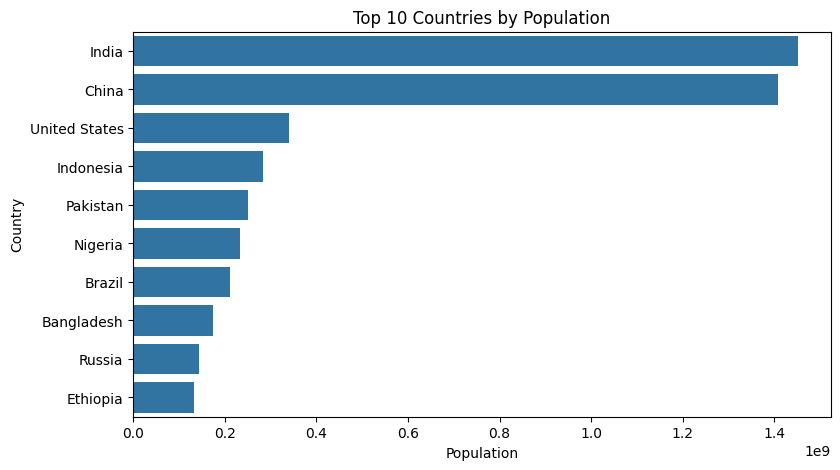

In [110]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=top_population,
    x="Population",
    y="Country"
)

plt.title("Top 10 Countries by Population")
plt.xlabel("Population")
plt.ylabel("Country")

plt.show()

In [111]:
top_density = df.sort_values(
    "Population_Density",
    ascending=False
).head(10)

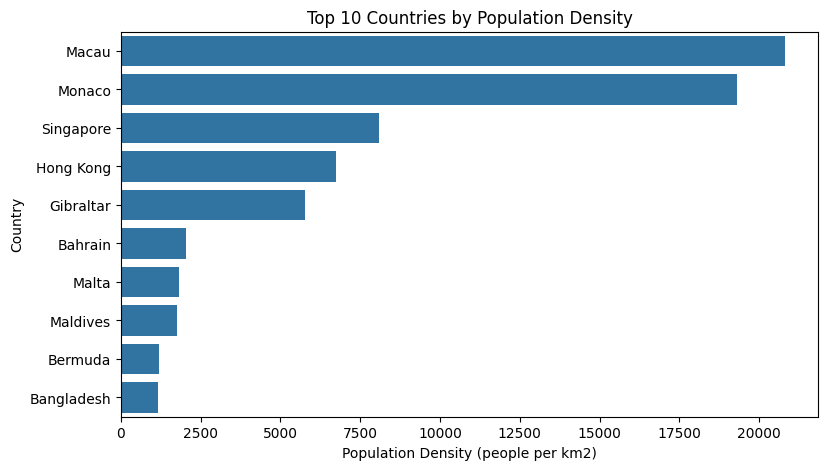

In [112]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=top_density,
    x="Population_Density",
    y="Country"
)

plt.title("Top 10 Countries by Population Density")
plt.xlabel("Population Density (people per km2)")
plt.ylabel("Country")

plt.show()

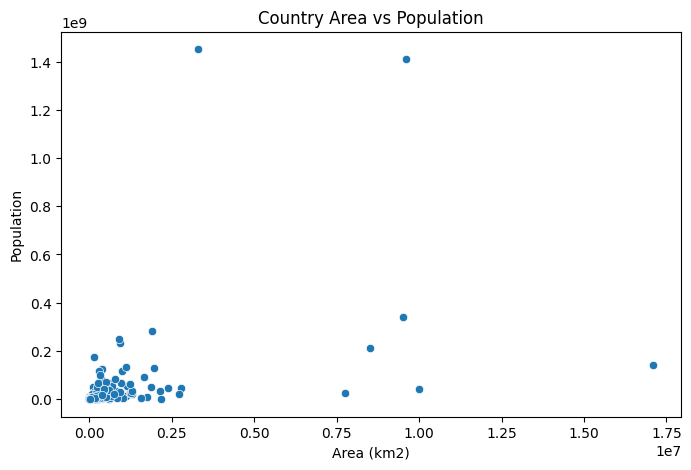

In [113]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Area_km2",
    y="Population"
)

plt.title("Country Area vs Population")
plt.xlabel("Area (km2)")
plt.ylabel("Population")

plt.show()

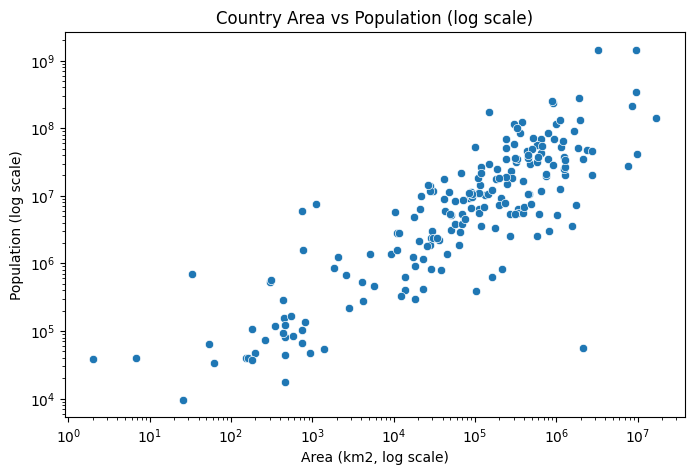

In [114]:

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Area_km2",
    y="Population"
)

plt.xscale("log")
plt.yscale("log")

plt.title("Country Area vs Population (log scale)")
plt.xlabel("Area (km2, log scale)")
plt.ylabel("Population (log scale)")

plt.show()

In [115]:
df.to_csv(
    "population_area_density.csv",
    index=False
)

## 8. Findings

- Number of countries in the final dataset:
- Country with the largest population:
- Country with the largest area:
- Country with the highest density (and why it is small):
- Correlation between area and population (Pearson / Spearman):
- Rows lost in the merge and why: